# Competitive Suppression

Presented at the start of the results, this contains an analysis of the impact of competitive suppression, within the context of the doubling time.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib import colormaps

sys.path.append("../utils")
from myUtils import convert_ode_parameters, calc_critical_treatment_threshold, calc_critical_treatment_interval, test_progression, TreatmentListToTS, ExtractTreatmentFromDf
from odeModels import LotkaVolterraModel, CompetitionModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'Delta_T':'#66419e'}

In [3]:
def PlotDrug(dataDf, ax, color, plotDrugAsBar=True, currDrugBarPosition = 1.2, drugBarHeight = 0.2, line_max=None, **kwargs):
    # Generate drug data as time series from list
    drugConcentrationItem = TreatmentListToTS(treatmentList=ExtractTreatmentFromDf(dataDf),
                                                    tVec=dataDf['Time'])
    try:
        drugConcentrationVec += drugConcentrationItem
        max_dose = max(max_dose, np.max(drugConcentrationItem))
    except UnboundLocalError:
        drugConcentrationVec = drugConcentrationItem
        max_dose = np.max(drugConcentrationItem)

    # Plot as bars across top of plot. Cleaner, but can be harder to see alignment with tumour trajectory.
    # Rescale to make it fit within the bar at the top of the plot
    drugConcentrationVec = drugConcentrationVec * drugBarHeight + currDrugBarPosition
    line_max = dataDf['Time'].max() if line_max is None else line_max
    ax.fill_between(x=dataDf['Time'], y1=currDrugBarPosition, y2=drugConcentrationVec, linewidth=0.0,
                     alpha=0.5, step="post", label="Drug Concentration", color=color, **kwargs)
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition, linewidth=3, color="black")
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition + drugBarHeight, linewidth=3, color="black")


def Plot(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_limit = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    currModelPredictionDf = pd.melt(df, id_vars=['Time'], value_vars=["TumourSize"])
    ax.plot(currModelPredictionDf['Time'], currModelPredictionDf['value'], linewidth=linewidth, **kwargs)

    PlotDrug(df, ax, 'k', plotDrugAsBar = True, currDrugBarPosition = 0.12, drugBarHeight = 0.02, line_max=drug_limit)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    # plt.tight_layout()

In [7]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_limit = None, colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', '--', '--']
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, 'k', plotDrugAsBar = True, line_max=drug_limit, currDrugBarPosition = 1.25)
    # ax.hlines(xmin=0, xmax=max(df['Time']), y=1, linestyles=":", linewidth=6, color='grey')
    ax.hlines(xmin=0, xmax=max(df['Time']), y=1.2, linestyles=":", linewidth=6, color='red')

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.set_ylim(0, 1.4)
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)
    plt.tight_layout()

## Panel A - Treatment Comparison

In [8]:
# Notebook params
file_path = os.path.dirname(os.path.abspath("__file__"))
model_path = os.path.join(os.pardir, file_path, "models")
results_path = os.path.join(file_path, "data", "Fig2")
runFromScratch = True

odeParamDic = convert_ode_parameters(n0=0.75, rFrac=0.001, cost=0, turnover=0)

## Impact of Competitive Supression

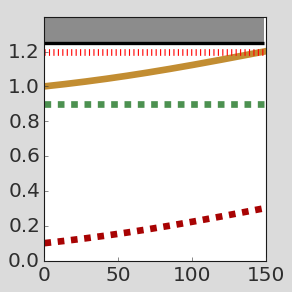

In [9]:
# Compute performance under continuous therapy
odeParamDic = convert_ode_parameters(n0=0.9, rFrac=0, cost=0, turnover=0)
odeParamDic['R0'] = 0.1; odeParamDic['K']=1.5
ct_model = CompetitionModel(method='RK45')
ct_model.SetParams(**odeParamDic)
ct_model.Simulate([[0, 300, 1]])
ct_model.Trim(dt=1)
# ct_model.resultsDf[['TumourSize', 'S', 'R']] /= odeParamDic['n0']
ct_model.resultsDf = ct_model.resultsDf[ct_model.resultsDf['TumourSize'] <  1.2]
ct_model.ttp = max(ct_model.resultsDf['Time'])

plt.rcParams['font.size'] = '18'
fix, ax = plt.subplots(1,1,figsize=(4,4))

palette = {'TumourSize': colors['CT'], 'S': colors['Sensitive'], 'R': colors['Resistant']}
Plot_method(ct_model.resultsDf, ax=ax, legend=False, colors = palette, linewidth=6)
# ax.axvline(ct_model.ttp, 0, 0.85, linestyle=':', linewidth = 6, color=colors["CT"], zorder=0)

ax.set_xlim(0, 148); ax.set_xticks([0, 50, 100, 150])
plt.savefig("figures/SI_competition_CT.pdf")

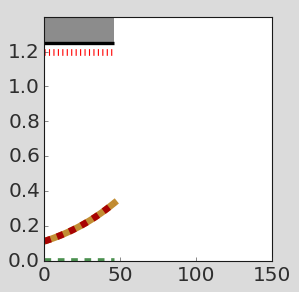

In [10]:
# Compute performance under continuous therapy
odeParamDic['S0'] = 0
ct_model = CompetitionModel(method='RK45')
ct_model.SetParams(**odeParamDic)
ct_model.Simulate([[0, 2000, 1]])
ct_model.Trim(dt=1)
ct_model.resultsDf[['TumourSize', 'S', 'R']] /= odeParamDic['n0']
ct_model.resultsDf = ct_model.resultsDf[ct_model.resultsDf['TumourSize'] < ct_model.resultsDf['TumourSize'][0] * 3]
ct_model.ttp = max(ct_model.resultsDf['Time'])

plt.rcParams['font.size'] = '18'
fix, ax = plt.subplots(1,1,figsize=(4,4))

palette = {'TumourSize': colors['CT'], 'S': colors['Sensitive'], 'R': colors['Resistant']}
Plot_method(ct_model.resultsDf, ax=ax, legend=False, colors = palette, linewidth=6)
# ax.axvline(ct_model.ttp, 0, 0.85, linestyle=':', linewidth = 6, color=colors["CT"], zorder=0)
ax.set_xlim(0, 148); ax.set_xticks([0, 50, 100, 150])

plt.savefig("figures/SI_no_competition_CT.pdf")

## Quantify the impact of competitive supression on the doubling time

In [11]:
def calc_delta_T(dR, K, rR, R0, **kwargs):
    T_plus_log = (rR * R0) / (dR * K + rR * R0)
    T_plus = (np.log(1 + T_plus_log) - np.log(2)) / dR

    T_minus_log = (rR * R0) / (dR * K - rR * K + rR * R0)
    T_minus = (np.log(1 + T_minus_log) - np.log(2)) / (dR - rR)
    print(T_plus, T_minus)
    return T_plus - T_minus

In [12]:
def calc_doubling_time(kappa, dR, K, rR, R0, **kwargs):
    T_log = (rR * R0) / (dR * K - (1 - kappa) * rR * K + rR * R0)
    T = (np.log(1 + T_log) - np.log(2)) / (dR - (1 - kappa) * rR)
    return T

def calc_doubling_benefit(kappa, dR, K, rR, R0, **kwargs):
    T_plus = calc_doubling_time(kappa, dR, K, rR, R0, **kwargs)
    T_minus = calc_doubling_time(0, dR, K, rR, R0, **kwargs)
    return (T_plus - T_minus) / T_minus

In [13]:
odeParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=0.1, turnover=0.1)
print(odeParamDic)
print(test_progression(odeParamDic))

kappa = 0.7
T_plus = calc_doubling_time(kappa=kappa, **odeParamDic)
T_minus = calc_doubling_time(kappa=0, **odeParamDic)
print(f"T_plus = {T_plus:.0f}, T_minus = {T_minus:.0f}, T_plus - T_minus = {T_plus - T_minus:.0f}")

{'n0': 1, 'rS': 0.027, 'rR': 0.0243, 'dS': 0.0027, 'dR': 0.0027, 'dD': 1.5, 'K': 1.0, 'D': 0, 'theta': 1, 'DMax': 1.0, 'S0': 0.999, 'R0': 0.001}
False
T_plus = 152, T_minus = 32, T_plus - T_minus = 120


T+ Doubling time: 152.0
T- Doubling time: 32.0


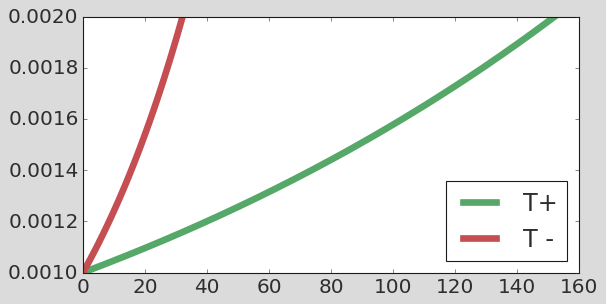

In [14]:
# Compute performance under rule of thumb
TPlusParamDic = odeParamDic
TPlusParamDic['dD'] = 0; TPlusParamDic['dS'] = 0; TPlusParamDic['rS'] = 0; TPlusParamDic['S0'] = kappa  # Artificially enforce dS/dT = 0
T_plus_model = LotkaVolterraModel(method='RK45'); T_plus_model.SetParams(**TPlusParamDic)
T_plus_model.Simulate([[0, 2000, 1]]); T_plus_model.Trim(dt=1)
T_plus_model.resultsDf = T_plus_model.resultsDf[T_plus_model.resultsDf['R'] < TPlusParamDic['R0'] * 2]#T_plus_model.resultsDf['R'].iloc[0] * 2]
print("T+ Doubling time: " + str(max(T_plus_model.resultsDf['Time'])))

# Compute performance under continuous therapy
TMinusParamDic = odeParamDic.copy()
TMinusParamDic['S0'] = 0; TMinusParamDic['n0'] = TMinusParamDic['R0']; TMinusParamDic['rFrac'] = 1
T_minus_model = LotkaVolterraModel(method='RK45'); T_minus_model.SetParams(**TMinusParamDic)
T_minus_model.Simulate([[0, 2000, 1]]); T_minus_model.Trim(dt=1)
T_minus_model.resultsDf = T_minus_model.resultsDf[T_minus_model.resultsDf['R'] < TMinusParamDic['R0'] * 2] #T_minus_model.resultsDf['R'].iloc[0] * 2]
print("T- Doubling time: " + str(max(T_minus_model.resultsDf['Time'])))

fix, ax = plt.subplots(1,1,figsize=(8,4))
ax.plot(T_plus_model.resultsDf['Time'], T_plus_model.resultsDf['R'], linewidth=6, color='g', label="T+")
ax.plot(T_minus_model.resultsDf['Time'], T_minus_model.resultsDf['R'], linewidth=6, color='r', label="T -"); ax.legend(loc=4);

## Properties of Doubling Time Function

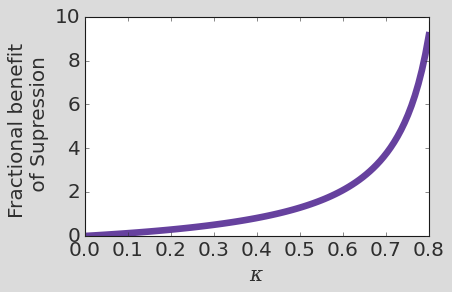

In [15]:
kappa_range = np.linspace(0, 0.8, 100)
doubling_time_benefit = [calc_doubling_benefit(kappa=K, **odeParamDic) for K in kappa_range]

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color=colors['Delta_T'])

ax.set_xlabel(r'$\kappa$'); ax.set_ylabel("Fractional benefit \n of Supression")
plt.tight_layout()
plt.show()


In [16]:
# Change colour scheme to have one color per variable
# with intensity to match magnitude (approx)

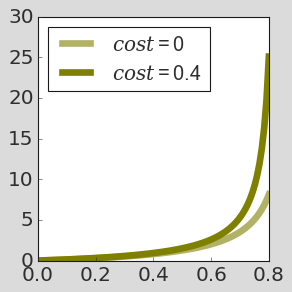

In [53]:
# Changing cost
low_cost = 0; high_cost = 0.4

lowParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=low_cost, turnover=0.1)
doubling_time_benefit = [calc_doubling_benefit(kappa=K, **lowParamDic) for K in kappa_range]

highParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=high_cost, turnover=0.1)
doubling_time_benefit_new = [calc_doubling_benefit(kappa=K, **highParamDic) for K in kappa_range]

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color='olive', alpha=0.6,
        label = f"$cost = {low_cost}$")
ax.plot(kappa_range, doubling_time_benefit_new, linewidth=6, color='olive',
        label = f"$cost = {high_cost}$")

ax.set_xticks(ax.get_xticks()[::2]); ax.tick_params(top=False, right=False)
# ax.set_xlabel('Cost'); ax.set_ylabel("Fractional benefit \n of Supression")
ax.legend(loc=2, fontsize=18); plt.tight_layout()
plt.savefig("figures/SI_cost_sensitivity.pdf")
plt.show()

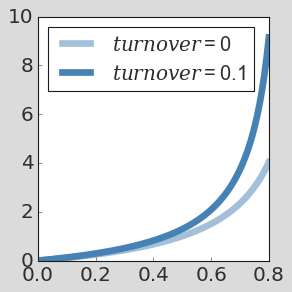

In [54]:
# Changing turnover
low_turnover = 0; high_turnover = 0.1

lowParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=0.1, turnover=low_turnover)
doubling_time_benefit = [calc_doubling_benefit(kappa=K, **lowParamDic) for K in kappa_range]

highParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=0.1, turnover=high_turnover)
doubling_time_benefit_new = [calc_doubling_benefit(kappa=K, **highParamDic) for K in kappa_range]

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color='steelblue', alpha=0.5,
        label = f"$turnover = {low_turnover}$")
ax.plot(kappa_range, doubling_time_benefit_new, linewidth=6, color='steelblue',
        label = f"$turnover = {high_turnover}$")

ax.set_xticks(ax.get_xticks()[::2]); ax.tick_params(top=False, right=False)
# ax.set_xlabel('Turnover'); ax.set_ylabel("Fractional benefit \n of Supression")
ax.legend(loc=2, fontsize=18); plt.tight_layout()
plt.savefig("figures/SI_turnover_sensitivity.pdf")
plt.show()

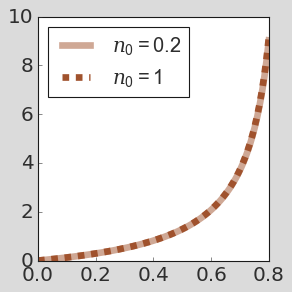

In [55]:
# Changing n0
low_n0 = 0.2; high_n0 = 1

lowParamDic = convert_ode_parameters(n0=low_n0, rFrac=0.001, cost=0.1, turnover=0.1)
doubling_time_benefit = [calc_doubling_benefit(kappa=K, **lowParamDic) for K in kappa_range]

highParamDic = convert_ode_parameters(n0=high_n0, rFrac=0.001, cost=0.1, turnover=0.1)
doubling_time_benefit_new = [calc_doubling_benefit(kappa=K, **highParamDic) for K in kappa_range]

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color='sienna', alpha=0.5,
        label = f"$n_{0} = {low_n0}$")
ax.plot(kappa_range, doubling_time_benefit_new, linewidth=6, color='sienna', linestyle='--',
        label = f"$n_{0} = {high_n0}$")

ax.set_xticks(ax.get_xticks()[::2]); ax.tick_params(top=False, right=False)
# ax.set_xlabel(r'$n_{0}$'); ax.set_ylabel("Fractional benefit \n of Supression")
ax.legend(loc=2, fontsize=18); plt.tight_layout()
plt.savefig("figures/SI_n0_sensitivity.pdf")
plt.show()

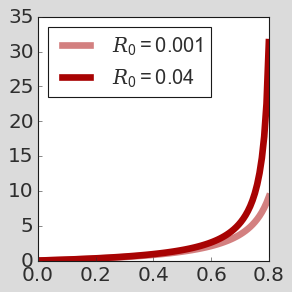

In [56]:
# Changing R0
low_rFrac = 0.001; high_rFrac = 0.04

lowParamDic = convert_ode_parameters(n0=1, rFrac=low_rFrac, cost=0.1, turnover=0.1)
doubling_time_benefit = [calc_doubling_benefit(kappa=K, **lowParamDic) for K in kappa_range]

highParamDic = convert_ode_parameters(n0=1, rFrac=high_rFrac, cost=0.1, turnover=0.1)
doubling_time_benefit_new = [calc_doubling_benefit(kappa=K, **highParamDic) for K in kappa_range]

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color=colors['Resistant'], alpha=0.5,
        label = f"$R_{0} = {low_rFrac}$")
ax.plot(kappa_range, doubling_time_benefit_new, linewidth=6, color=colors['Resistant'], 
        label = f"$R_{0} = {high_rFrac}$")

ax.set_xticks(ax.get_xticks()[::2]); ax.tick_params(top=False, right=False)
# ax.set_xlabel(r'$R_{0}$'); ax.set_ylabel("Fractional benefit \n of Supression")
ax.legend(loc=2, fontsize=18); plt.tight_layout()
plt.savefig("figures/SI_r0_sensitivity.pdf")
plt.show()

In [57]:
lowParamDic = convert_ode_parameters(n0=0.1, rFrac=0.001, cost=0.1, turnover=0.1)
print(lowParamDic)


{'n0': 0.1, 'rS': 0.027, 'rR': 0.0243, 'dS': 0.0027, 'dR': 0.0027, 'dD': 1.5, 'K': 1.0, 'D': 0, 'theta': 1, 'DMax': 1.0, 'S0': 0.0999, 'R0': 0.0001}


/var/folders/by/xwl2vmrj5dl9941qxr6lr2t4002mml/T/ipykernel_96247/2786255877.py:3: RuntimeWarning: invalid value encountered in log
  T = (np.log(1 + T_log) - np.log(2)) / (dR - (1 - kappa) * rR)


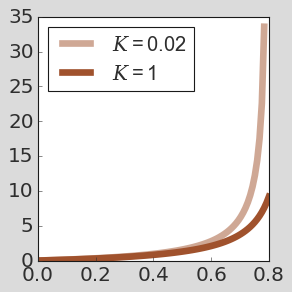

In [58]:
# Changing K
low_K = 20*odeParamDic['R0']; high_K = 1
# low_K = odeParamDic['R0']; high_K = 1

lowParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=0.1, turnover=0.1)
lowParamDic['K'] = low_K
doubling_time_benefit = [calc_doubling_benefit(kappa=k, **lowParamDic) for k in kappa_range]

highParamDic = convert_ode_parameters(n0=1, rFrac=0.001, cost=0.1, turnover=0.1)
highParamDic['K'] = high_K
doubling_time_benefit_new = [calc_doubling_benefit(kappa=k, **highParamDic) for k in kappa_range]

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.plot(kappa_range, doubling_time_benefit, linewidth=6, color='sienna', alpha=0.5,
        label = f"$K = {low_K}$")
ax.plot(kappa_range, doubling_time_benefit_new, linewidth=6, color='sienna', 
        label = f"$K = {high_K}$")

ax.set_xticks(ax.get_xticks()[::2]); ax.tick_params(top=False, right=False)
# ax.set_xlabel(r'$n_{0}$'); ax.set_ylabel("Fractional benefit \n of Supression")
ax.legend(loc=2, fontsize=18); plt.tight_layout()
plt.savefig("figures/SI_K_sensitivity.pdf")
plt.show()